In [31]:
import pandas as pd

# upload crash_reports.csv to your Colab files (root /) so this path works
df = pd.read_csv("../crash_reports.csv", dtype={"Local Case Number": str})
dates = df["Crash Date/Time"]
df["Crash Date/Time"]= pd.to_datetime(dates, format="%m/%d/%Y %I:%M:%S %p")
l = ["Weather", "Light", "Surface Condition", "Injury Severity", "Vehicle Damage Extent", "Collision Type", "Vehicle Going Dir", "Agency Name"]
for i in l:
  df[i] = df[i].str.strip().str.upper()

#dupes - sometimes a col can have another way of naming the same thing
fixes = {"Weather": {"RAIN": "RAINING", "FOG, SMOG, SMOKE": "FOGGY", "SLEET OR HAIL": "SLEET", "SEVERE CROSSWINDS": "SEVERE WINDS"}, "Light": {"DARK - LIGHTED": "DARK LIGHTS ON", "DARK - NOT LIGHTED": "DARK NO LIGHTS", "DARK - UNKNOWN LIGHTING": "DARK -- UNKNOWN LIGHTING"}, "Surface Condition": {"ICE/FROST": "ICE", "WATER (STANDING, MOVING)": "WATER(STANDING/MOVING)"}, "Vehicle Going Dir": {"NORTHBOUND": "NORTH", "SOUTHBOUND": "SOUTH", "EASTBOUND": "EAST", "WESTBOUND": "WEST"}, "Agency Name": {"MONTGOMERY": "MONTGOMERY COUNTY POLICE", "ROCKVILLE": "ROCKVILLE POLICE DEPARTME", "GAITHERSBURG": "GAITHERSBURG POLICE DEPAR", "TAKOMA": "TAKOMA PARK POLICE DEPART", "MCPARK": "MARYLAND-NATIONAL CAPITAL"}, "Collision Type": {"FRONT TO REAR": "SAME DIR REAR END", "FRONT TO FRONT": "HEAD ON", "SIDESWIPE, SAME DIRECTION": "SAME DIRECTION SIDESWIPE", "SIDESWIPE, OPPOSITE DIRECTION": "OPPOSITE DIRECTION SIDESWIPE"}}
for col in fixes:
    df[col] = df[col].replace(fixes[col])
df["Vehicle Year"] = df["Vehicle Year"].apply(lambda x: x if (x >= 1900 and x<=2026) else None).astype("Int64")


## Hypothesis test: injury severity vs light condition

**Question:** Is a driver's injury severity independent of the light condition at the time of the crash?

- **H0:** Injury severity and light condition are independent.
- **H1:** Injury severity and light condition are not independent.
- **Significance level:** alpha = 0.05
- **Test:** chi-square test of independence, since both variables are categorical.

In [32]:
chi_df = df.dropna(subset=["Injury Severity"])

light_levels = ["DAYLIGHT", "DAWN", "DUSK", "DARK LIGHTS ON", "DARK NO LIGHTS"]
chi_df = chi_df[chi_df["Light"].isin(light_levels)]

print("rows kept:", len(chi_df), "of", len(df))

severity_levels = ["NO APPARENT INJURY", "POSSIBLE INJURY", "SUSPECTED MINOR INJURY", "SUSPECTED SERIOUS INJURY", "FATAL INJURY"]
chi_table = pd.crosstab(chi_df["Light"], chi_df["Injury Severity"])
chi_table = chi_table.loc[light_levels, severity_levels]
chi_table

rows kept: 189026 of 194726


Injury Severity,NO APPARENT INJURY,POSSIBLE INJURY,SUSPECTED MINOR INJURY,SUSPECTED SERIOUS INJURY,FATAL INJURY
Light,,,,,
DAYLIGHT,107120,13270,9200,1023,77
DAWN,3015,383,264,34,4
DUSK,3501,382,290,46,10
DARK LIGHTS ON,36766,4068,3344,407,58
DARK NO LIGHTS,4624,568,478,70,24


In [33]:
from scipy.stats import chi2_contingency

chi_stat, chi_p, chi_dof, chi_expected = chi2_contingency(chi_table)
print(f"chi-square statistic: {chi_stat}")
print(f"degrees of freedom: {chi_dof}")
print(f"p-value: {chi_p}")

chi-square statistic: 183.4990599677264
degrees of freedom: 16
p-value: 1.6731531566546916e-30


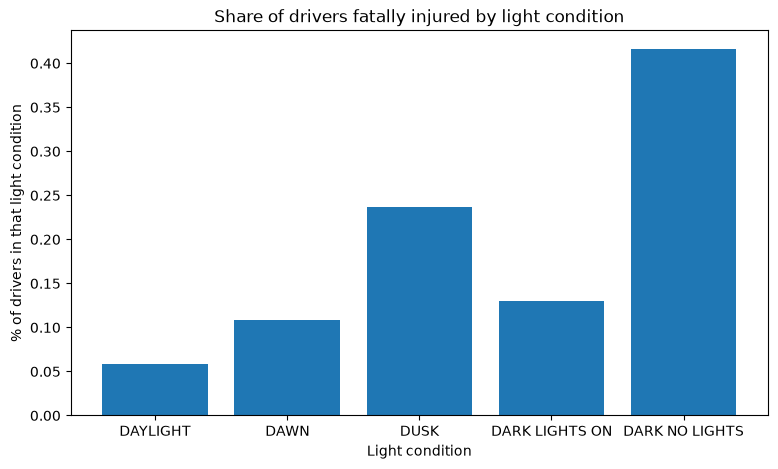

In [34]:
import matplotlib.pyplot as plt

chi_totals = chi_df["Light"].value_counts()
chi_fatal = chi_table["FATAL INJURY"] / chi_totals[light_levels] * 100

plt.figure(figsize=(9, 5))
plt.bar(chi_fatal.index, chi_fatal)
plt.title("Share of drivers fatally injured by light condition")
plt.xlabel("Light condition")
plt.ylabel("% of drivers in that light condition")
plt.show()

## Conclusion

After running the chi-squared test, the resulted a p-value of about 1.7e-30 which is way smaller than our alpha of 0.05 so we reject the null hypothesis. This means that injury severity and light condition are not independent and are related to each other.

Based off the plot, we can see that drivers in the dark with no street lights had the highest share of fatal injuries at 0.42% which is about 7 times the 0.06% in daylight. When it's dark but the street lights are on, it drops to 0.13%, which is a lot closer to daylight.

However, there are around 189,000 drivers so even small differences can show up as significant, and the share of drivers that got injured only goes from about 17% to 20% across all light conditions. Also this only shows that the two are related, not that darkness causes worse injuries, since crashes in the dark could also be different in other ways like speed or the type of road.

## Test: posted speed limit and injury status

We used Welch's two-sample t-test to compare mean posted speed limits for injury crashes and crashes with no apparent injury. This test allows the groups to have different variances.

H0: The mean posted speed limits are equal.  
H1: The mean posted speed limits differ.  
Significance level: 0.05.

We counted each crash once and included possible injuries in the injury group. We excluded crashes with unknown injury status or missing, zero, or conflicting speed limits.


Total crashes:  98595
Injury crashes: 26171
No apparent injury crashes: 72424
Mean speed limit, injury: 35.62 mph
Mean speed limit, no apparent injury: 31.39 mph
p-value: 0.0
Reject the null since the means differ.


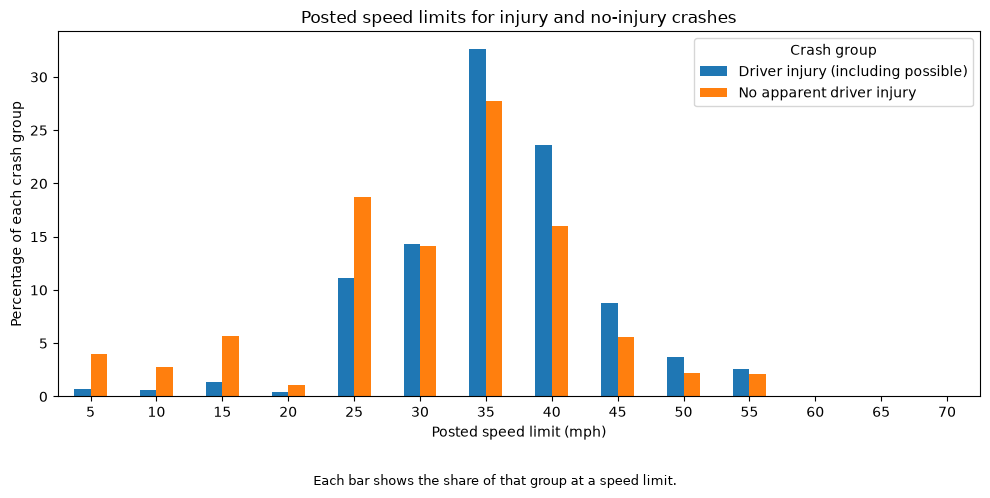

In [35]:
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Prep the data using df from the start
speed_df = df[["Report Number", "Injury Severity", "Speed Limit"]].copy()
speed_df["Speed Limit"] = pd.to_numeric(speed_df["Speed Limit"], errors="coerce")

injury_categories = [
    "POSSIBLE INJURY",
    "SUSPECTED MINOR INJURY",
    "SUSPECTED SERIOUS INJURY",
    "FATAL INJURY",
]
speed_df["injury"] = speed_df["Injury Severity"].isin(injury_categories)
speed_df["known_injury"] = speed_df["Injury Severity"].isin(
    injury_categories + ["NO APPARENT INJURY"]
)
speed_df["valid_speed"] = speed_df["Speed Limit"] > 0

# Count each crash once
reports = speed_df.groupby("Report Number")
crash_speed = pd.DataFrame()
crash_speed["speed_limit"] = reports["Speed Limit"].first()
crash_speed["injury"] = reports["injury"].any()

# Keep crashes with known injuries and one valid speed limit
known_injuries = reports["known_injury"].all()
valid_speeds = reports["valid_speed"].all()
one_speed_limit = reports["Speed Limit"].nunique() == 1
crash_speed = crash_speed[known_injuries & valid_speeds & one_speed_limit].copy()

# Let's compare the two groups
injury_speed = crash_speed.loc[crash_speed["injury"], "speed_limit"]
no_injury_speed = crash_speed.loc[~crash_speed["injury"], "speed_limit"]

print("Total crashes: ", len(injury_speed) + len(no_injury_speed))
print("Injury crashes:", len(injury_speed))
print("No apparent injury crashes:", len(no_injury_speed))
print("Mean speed limit, injury:", round(injury_speed.mean(), 2), "mph")
print("Mean speed limit, no apparent injury:", round(no_injury_speed.mean(), 2), "mph")


result = ttest_ind(injury_speed, no_injury_speed, equal_var=False)
p_value = result.pvalue

# Its zero here since the p value it's too small for python to represent
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject the null since the means differ.")
else:
    print("Fail to reject the null since theres no clear difference.")

# Compare percentages because the groups have different sizes
crash_speed["group"] = crash_speed["injury"].map(
    {True: "Driver injury (including possible)", False: "No apparent driver injury"}
)
percentages = pd.crosstab(
    crash_speed["speed_limit"], crash_speed["group"], normalize="columns"
) * 100

percentages.plot.bar(figsize=(10, 5))
plt.title("Posted speed limits for injury and no-injury crashes")
plt.xlabel("Posted speed limit (mph)")
plt.ylabel("Percentage of each crash group")
plt.legend(title="Crash group")
plt.xticks(rotation=0)
plt.figtext(
    0.5, 0.02,
    "Each bar shows the share of that group at a speed limit.",
    ha="center", fontsize=9
)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


## What we found with this test

We included 98,595 crashes: 26,171 with a driver injury and 72,424 with no apparent driver injury. Possible injuries are included in the injury group.

The mean posted speed limit was 35.62 mph for injury crashes and 31.39 mph for crashes with no apparent injury, a difference of 4.24 mph. The p-value was below 0.001, so we reject H0.

The chart shows a larger share of injury crashes at 35 to 50 mph and a larger share of no-apparent-injury crashes at lower limits, especially 25 mph. The bars show percentages within each group, not the chance of injury at each speed limit.

There were only 53 included crashes at 60 mph, 34 at 65 mph, and 2 at 70 mph. Their bars are too small to see clearly, so we cannot draw strong conclusions about those limits.

## Conclusion

Injury crashes occurred on roads with higher posted speed limits on average. Speed limit could be useful in later analysis, but this does not mean higher limits caused injuries. These are posted limits, not actual driving speeds, and the results apply only to the reported crashes we included.


## Summary Statistics: Total Reported Crashes by Day  
Are there any temporal trends or outlier days for reported crashes over the years?

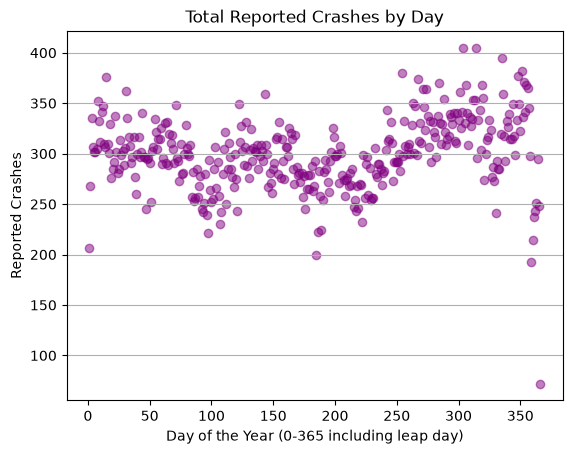

count    366.000000
mean     299.683060
std       36.026825
min       72.000000
25%      280.000000
50%      300.000000
75%      320.750000
max      405.000000
Name: count, dtype: float64


In [36]:
# Every vehicle in a crash gets an entry with the same report number, so keep only the first entry
days_df = df.drop_duplicates(subset='Report Number', keep='first')

# Days has the total frequency of crashes every day of the year
days = days_df['Crash Date/Time'].apply(lambda x: x.timetuple().tm_yday).value_counts()

plt.scatter(days.index, days, alpha=0.5, color='purple')
plt.grid(axis='y')
plt.title("Total Reported Crashes by Day")
plt.xlabel("Day of the Year (0-365 including leap day)")
plt.ylabel("Reported Crashes")
plt.show()

print(days.describe())

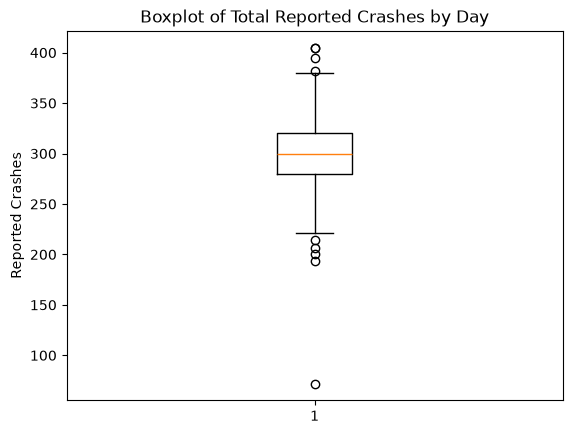

Upper Whisker: 381.875  Lower Whisker: 218.875
Outliers - (Day of the Year, Frequency):
(0,405)
(1,405)
(2,395)
(3,382)
(361,214)
(362,206)
(363,200)
(364,193)
(365,72)


In [37]:
# whiskers of box plot
lower = days.quantile(0.25) - 1.5 * (days.quantile(0.75) - days.quantile(0.25))
upper = days.quantile(0.75) + 1.5 * (days.quantile(0.75) - days.quantile(0.25))

plt.boxplot(days)
plt.title("Boxplot of Total Reported Crashes by Day")
plt.ylabel("Reported Crashes")
plt.show()

outlier_days = []
print("Upper Whisker:",upper, " Lower Whisker:", lower)
print("Outliers - (Day of the Year, Frequency):")
for i, x in enumerate(days):
    if x < lower or x > upper:
        print(f"({i},{x})")

## Conclusion  
By the scatter plot and summary statistics, there isn't a clear temporal pattern for the number crashes reported. The total of most days hover around the average of ~299.6 crash reports.  

However there are extreme outlier days around New Years we'll have to consider in future analysis. These outliers are likely explained by the holiday season - more people are driving after Christmas and before New Years, while less people are driving on New Years Eve and New Years day to celebrate.